In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa de montajes ejecuta el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y operarios necesarios por actividad se adjunta. La plantilla disponible es de **4 operarios** a jornada completa (40 horas semanales); no hay otros proyectos en marcha.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 4       , 2        ),
    ('B'     , '---'      , 2       , 4        ),
    ('C'     , 'A,B'      , 5       , 4        ),
    ('D'     , 'C'        , 3       , 3        ),
    ('E'     , 'B'        , 6       , 1        ),
    ('F'     , 'C,E'      , 1       , 4        ),
    ('G'     , 'D'        , 5       , 1        ),
    ('H'     , 'F,G'      , 3       , 2        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,4,2
B,---,2,4
C,"A,B",5,4
D,C,3,3
E,B,6,1
F,"C,E",1,4
G,D,5,1
H,"F,G",3,2


> **De: Jefe de proyecto**
> El cliente quiere las 20 semanas del plan con inicios más tempranos y no vamos a contratar a nadie. Las semanas en que hagan falta más de los que somos, se hacen horas extra y ya está: se pagan y punto.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 19 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **C7 — Cumplimiento de la ley y de las normas de seguridad.** El proyecto no puede planificarse incumpliendo una norma legal o de seguridad aunque salga más barato o más rápido; una actividad exigida por una norma no es una opción de compresión. *(cf. Código Ético del PMI, 2.3.1 y 2.2.1; ICB4, Perspectiva 3 «cumplimiento, estándares y regulaciones»; PMBOK 8, principio de calidad integrada.)*
- **Norma — jornada ordinaria máxima: 40 horas semanales de trabajo efectivo de promedio en cómputo anual** *(Estatuto de los Trabajadores, art. 34.1.)*
- **Norma — máximo de horas extraordinarias: 80 por trabajador y año, sin contar las compensadas con descanso en los cuatro meses siguientes** *(Estatuto de los Trabajadores (RDL 2/2015), art. 35.2.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Dibuje el diagrama de cargas con inicios más tempranos y obtenga, semana a semana, el exceso de operarios sobre los 4 disponibles. Traduzca el exceso a horas extraordinarias por operario en el año (reparto uniforme entre la plantilla).  "
pregunta_2 = "2. (A) Calcule la duración del proyecto si se respeta el límite de 4 operarios (asignación con límite) y, alternativamente, cuántos operarios haría falta contratar para cumplir las semanas del plan sin horas extra.  "
pregunta_3 = "3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse el plan del jefe de proyecto? Justifique con la cifra.  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de proyecto y al cliente? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Dibuje el diagrama de cargas con inicios más tempranos y obtenga, semana a semana, el exceso de operarios sobre los 4 disponibles. Traduzca el exceso a horas extraordinarias por operario en el año (reparto uniforme entre la plantilla).  

2. (A) Calcule la duración del proyecto si se respeta el límite de 4 operarios (asignación con límite) y, alternativamente, cuántos operarios haría falta contratar para cumplir las semanas del plan sin horas extra.  

3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse el plan del jefe de proyecto? Justifique con la cifra.  

4. (C) ¿Qué propone al jefe de proyecto y al cliente? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
plantilla, jornada, maximo_horas_extra = 4, 40, 80
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = \max\{0+4,\ 0+2\} = 4$ &nbsp; (A, B)
- $T_{E} = 0+2 = 2$ &nbsp; (B)
- $T_{D} = 4+5 = 9$ &nbsp; (C)
- $T_{F} = \max\{4+5,\ 2+6\} = 9$ &nbsp; (C, E)
- $T_{G} = 9+3 = 12$ &nbsp; (D)
- $T_{H} = \max\{9+1,\ 12+5\} = 17$ &nbsp; (F, G)
- $T_{\mathrm{Fin}} = 17+3 = 20$ &nbsp; (H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 20$
- $T_{H}^{*} = 20-3 = 17$ &nbsp; (Fin)
- $T_{G}^{*} = 17-5 = 12$ &nbsp; (H)
- $T_{F}^{*} = 17-1 = 16$ &nbsp; (H)
- $T_{D}^{*} = 12-3 = 9$ &nbsp; (G)
- $T_{E}^{*} = 16-6 = 10$ &nbsp; (F)
- $T_{C}^{*} = \min\{9-5,\ 16-5\} = 4$ &nbsp; (D, F)
- $T_{B}^{*} = \min\{4-2,\ 10-2\} = 2$ &nbsp; (C, E)
- $T_{A}^{*} = 4-4 = 0$ &nbsp; (C)
- $T_{\mathrm{Inicio}}^{*} = \min\{0-0,\ 2-0\} = 0$ &nbsp; (A, B)

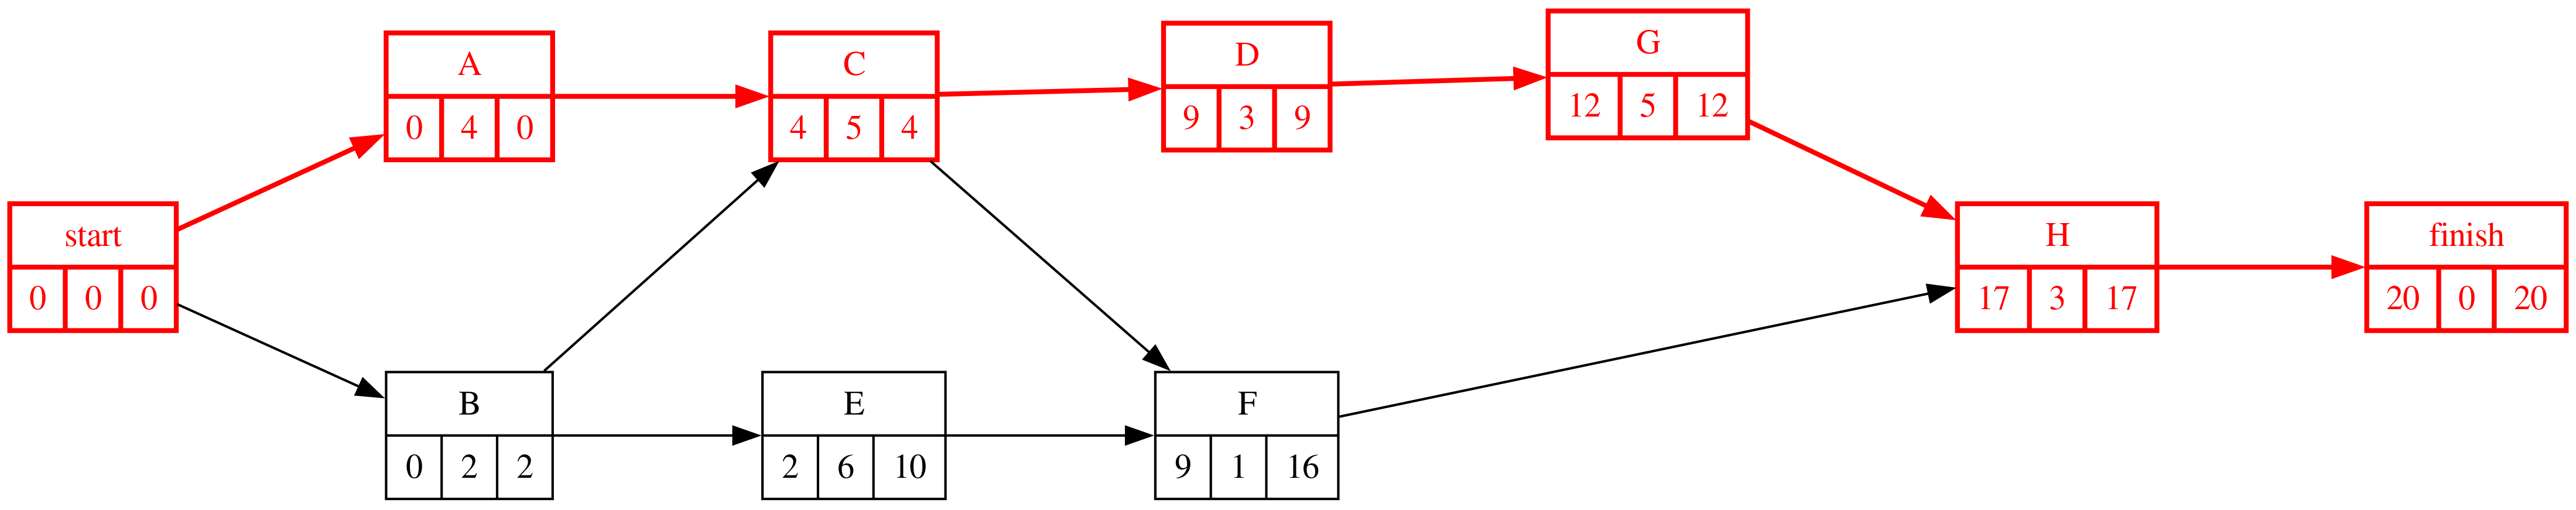

In [8]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Dibuje el diagrama de cargas con inicios más tempranos y obtenga, semana a semana, el exceso de operarios sobre los 4 disponibles. Traduzca el exceso a horas extraordinarias por operario en el año (reparto uniforme entre la plantilla).  

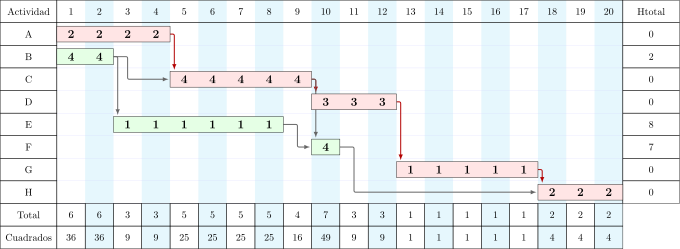

In [10]:
#| fig-cap: "Gantt con inicios más tempranos y carga de operarios"
#| label: fig-ganttCargas
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

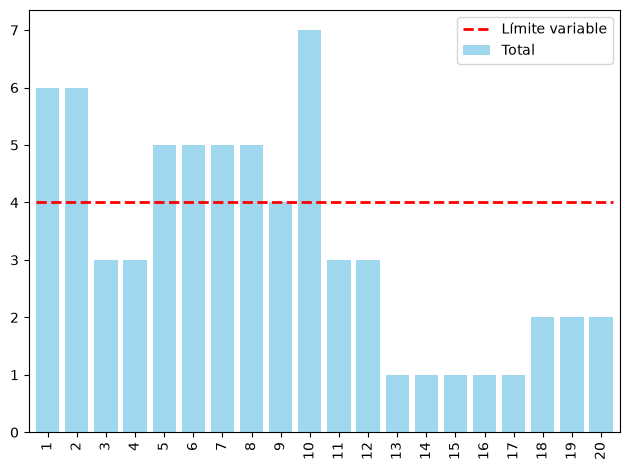

In [11]:
#| fig-cap: "Diagrama de cargas frente a la plantilla disponible"
#| label: fig-cargas
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=[plantilla])

In [12]:
#| tbl-cap: "Exceso de operarios y horas extraordinarias semana a semana"
#| label: tbl-exceso
exceso = (cargas - plantilla).clip(lower=0)
tabla = pd.DataFrame({'operarios necesarios': cargas, 'exceso sobre la plantilla': exceso,
                      'horas extra de la semana': exceso * jornada, 'horas extra por operario': exceso * jornada / plantilla})
tabla.loc['Total'] = tabla.sum()
horas_persona = float(tabla.loc['Total', 'horas extra por operario'])
display(tabla.round(1).T)
Markdown(f'''Pico de **{int(cargas.max())}** operarios frente a {plantilla}; exceso en {int((exceso > 0).sum())} semanas; **{horas_persona:.0f} horas extraordinarias por operario** en el año (máximo legal: {maximo_horas_extra}).''')

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,Total
operarios necesarios,6.0,6.0,3.0,3.0,5.0,5.0,5.0,5.0,4.0,7.0,3.0,3.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,66.0
exceso sobre la plantilla,2.0,2.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.0
horas extra de la semana,80.0,80.0,0.0,0.0,40.0,40.0,40.0,40.0,0.0,120.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,440.0
horas extra por operario,20.0,20.0,0.0,0.0,10.0,10.0,10.0,10.0,0.0,30.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,110.0


Pico de **7** operarios frente a 4; exceso en 7 semanas; **110 horas extraordinarias por operario** en el año (máximo legal: 80).

## Apartado 2

In [13]:
display(Markdown(pregunta_2))

2. (A) Calcule la duración del proyecto si se respeta el límite de 4 operarios (asignación con límite) y, alternativamente, cuántos operarios haría falta contratar para cumplir las semanas del plan sin horas extra.  

In [14]:
proyecto_asignado = proyecto.copy()
datos_asignados, gantt_asignado, dibujo = proyecto_asignado.asignar(data=datos_proyecto.copy(), duration_label='duration',
                                                                  resource_label='resources', maximo=[plantilla], report=False, params=GANTT_PARAMS)
duracion_con_limite = len(gantt_asignado.data.columns.drop('H_total'))
contratar = int(cargas.max()) - plantilla
Markdown(f'''Respetando los {plantilla} operarios el proyecto dura **{duracion_con_limite}** semanas ({duracion_con_limite - duracion} más que el plan); para cumplir las {duracion} semanas sin horas extra habría que contratar **{contratar}** operarios durante las semanas de pico (o nivelar primero y ver si baja el pico).''')

Respetando los 4 operarios el proyecto dura **23** semanas (3 más que el plan); para cumplir las 20 semanas sin horas extra habría que contratar **3** operarios durante las semanas de pico (o nivelar primero y ver si baja el pico).

In [15]:
#| fig-cap: "Gantt con asignación limitada a la plantilla"
#| label: fig-ganttAsignado
pinta_tikz(dibujo)

No file b4bc25866de74135822b1f72c06d2350.aux.
(/usr/share/texlive/texmf-dist/tex/context/base/mkii/supp-pdf.mkii
[Loading MPS to PDF converter (version 2006.09.02).]
) (/usr/share/texlive/texmf-dist/tex/latex/epstopdf-pkg/epstopdf-base.sty
(/usr/share/texlive/texmf-dist/tex/latex/latexconfig/epstopdf-sys.cfg))
! Undefined control sequence.
\GenericError  ...                                
                                                    #4  \errhelp \@err@     ...
l.215 ... transform shape, text= black ] ( 💤B )
                                                   at ( 0, -1.48000000000000...

? 
! Emergency stop.
\GenericError  ...                                
                                                    #4  \errhelp \@err@     ...
l.215 ... transform shape, text= black ] ( 💤B )
                                                   at ( 0, -1.48000000000000...

!  ==> Fatal error occurred, no output PDF file produced!
Transcript written on b4bc25866de74135822b1f72c06d2350.log.

None

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. (B) Según el criterio y la norma de referencia, ¿puede ejecutarse el plan del jefe de proyecto? Justifique con la cifra.  

**C7 y la norma.** El plan exige 110 horas extraordinarias por operario en el año, más de las 80 que fija el Estatuto de los Trabajadores (art. 35.2) salvo las compensadas con descanso, y supone sostener semanas por encima de la jornada ordinaria (art. 34.1). No es una opción de planificación: una actividad o un plan que incumple una norma no está en la tabla de opciones, por mucho que «se paguen». La cifra objetiva es la del apartado 1; con menos de 80 horas por operario el plan sería legal (y entonces la pregunta pasaría al bloque C: si conviene).

In [17]:
preguntas_test = [
    ('El máximo de horas extraordinarias por trabajador y año fijado por el Estatuto de los Trabajadores es…', ['80', '40', '120', 'no hay máximo si se pagan'],
     'Art. 35.2 ET: 80 horas al año, sin contar las compensadas con descanso.'),
    ('Un plan que exige más horas extra de las legales…', ['no es una opción: se descarta por C7', 'es válido si el cliente lo acepta', 'es válido si se pagan', 'depende del jefe de proyecto'],
     'El cumplimiento legal es condición previa, no un coste más en la tabla.'),
    ('Para cumplir el plazo sin horas extra la alternativa objetiva es…', ['contratar operarios para las semanas de pico o aceptar la duración con límite', 'reducir la calidad', 'no hacer el diagrama de cargas', 'cambiar las prelaciones'],
     'El diagrama de cargas da el pico y la asignación con límite da la nueva duración.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Ética 19 — horas extra')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_etica.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Ética 19 — horas extra

::Ética 19 — horas extra P1::El máximo de horas extraordinarias por trabajador y año fijado por el Estatuto de los Trabajadores es… {=80 ~40 ~120 ~no hay máximo si se pagan ####Art. 35.2 ET: 80 horas al año, sin contar las compensadas con descanso.}

::Ética 19 — horas extra P2::Un plan que exige más horas extra de las legales… {~depende del jefe de proyecto =no es una opción: se descarta por C7 ~es válido si se pagan ~es válido si el cliente lo acepta ####El cumplimiento legal es condición previa, no un coste más en la tabla.}

::Ética 19 — horas extra P3::Para cumplir el plazo sin horas extra la alternativa objetiva es… {~cambiar las prelaciones =contratar operarios para las semanas de pico o aceptar la duración con límite ~reducir la calidad ~no hacer el diagrama de cargas ####El diagrama de cargas da el pico y la asignación con límite da la nueva duración.}



## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de proyecto y al cliente? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados y qué pierde o gana cada uno; (2) formular al menos dos alternativas además de la que se propone en el enunciado; (3) someter cada alternativa a las tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería si se hiciera pública?) y reversibilidad (¿la aceptaría en el papel del afectado?)—; (4) decidir y redactar la comunicación con las cifras del bloque A. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Tabla de opciones para el jefe de proyecto: (1) aceptar 23 semanas con la plantilla; (2) contratar 3 operarios temporales las 7 semanas de pico y cumplir 20; (3) nivelar y combinar: parte en horas extra dentro de las 80 y el resto con refuerzo. Al cliente se le cuenta la opción elegida con su coste y su fecha; lo que no se le cuenta es que el plazo «se consigue» incumpliendo la ley (prueba de publicidad).